## Paso 0 — Cargamos las 18 tablas ya tipadas

Mismo patrón que los notebooks anteriores.


In [1]:
import pandas as pd
from pathlib import Path

RUTA_INTERIM = Path("../datos/interim")
ARCHIVOS_PARQUET = sorted(RUTA_INTERIM.glob("*.parquet"))
tablas = {archivo.stem: pd.read_parquet(archivo) for archivo in ARCHIVOS_PARQUET}
assert len(tablas) == 18, f"Se esperaban 18 tablas, se cargaron {len(tablas)}"
print(f"Tablas cargadas: {len(tablas)}")


Tablas cargadas: 18


## Paso 1 — Outliers en SAP con IQR, por línea de negocio (§10 del plan)

Aplicamos el método IQR sobre VALOR de tarifa-plaza, segmentado por
LineaNegocio (no sobre el total mezclado — mismo criterio de
"segmentar antes de comparar" que usó el EDA-1).


In [2]:
tarifa_plaza = tablas["tarifa-plaza-tblSAPTarifas-2022-09-01_a_hoy"]

def contar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    outliers = serie[(serie < limite_inferior) | (serie > limite_superior)]
    return len(outliers), len(serie), limite_inferior, limite_superior

for categoria, grupo in tarifa_plaza.groupby("lineaNegocioDescripcion"):
    n_outliers, n_total, lim_inf, lim_sup = contar_outliers_iqr(grupo["valor"])
    print(f"{categoria}: {n_outliers} outliers de {n_total} filas ({n_outliers/n_total*100:.1f}%) — rango normal: ${lim_inf:,.0f} a ${lim_sup:,.0f}")


Oferta de Expedición Devolución Contenedor: 48 outliers de 1031 filas (4.7%) — rango normal: $-1,500,000 a $4,900,000
Oferta de Expedición Interior a Puerto: 9 outliers de 2340 filas (0.4%) — rango normal: $-2,668,750 a $10,401,250
Oferta de Expedición Licitaciones: 0 outliers de 1 filas (0.0%) — rango normal: $3,556,418 a $3,556,418
Oferta de Expedición Nacional: 326 outliers de 13625 filas (2.4%) — rango normal: $-2,300,000 a $8,100,000
Oferta de Expedición Puerto a interior: 38 outliers de 6023 filas (0.6%) — rango normal: $-3,400,000 a $11,000,000


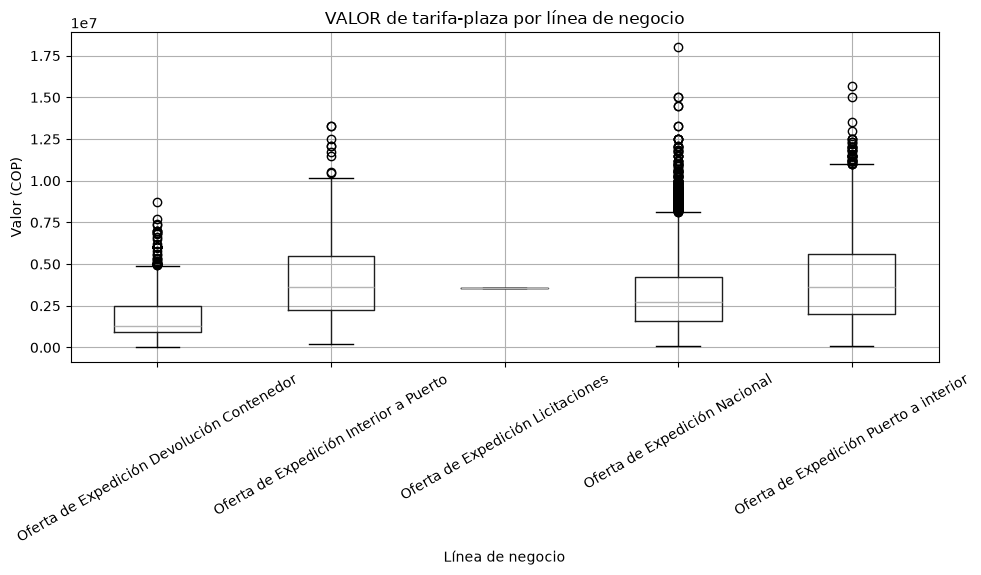

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))
tarifa_plaza.boxplot(column="valor", by="lineaNegocioDescripcion", ax=ax, rot=30)
ax.set_title("VALOR de tarifa-plaza por línea de negocio")
ax.set_xlabel("Línea de negocio")
ax.set_ylabel("Valor (COP)")
plt.suptitle("")
plt.tight_layout()
plt.savefig("../reportes/figures/outliers_valor_por_linea_negocio.png", dpi=150)
plt.show()


## Paso 2 — % de tarifas SAP ya vencidas hoy (§11 del plan)

Ya se sabía de una tarea anterior (HU-09.2) que la mayoría del catálogo
de tarifas SAP está vencido hoy (dejó de ser válido según su fecha de
`VIGENCIA`), sin que eso impida que el sistema lo siga usando — es un
sesgo a tener en cuenta si alguien usa `VIGENCIA` para filtrar "tarifas
activas". Lo confirmamos aquí con código propio, no solo citando el
dato anterior.


In [4]:
import pandas as pd

hoy = pd.Timestamp.now()
vencidas = (tarifa_plaza["vigencia"] < hoy).sum()
print(f"Tarifas vencidas hoy: {vencidas} de {len(tarifa_plaza)} ({vencidas/len(tarifa_plaza)*100:.1f}%)")


Tarifas vencidas hoy: 22245 de 23020 (96.6%)


## Síntesis del notebook 07 — Outliers, sesgos y vacíos (Fases 9-11, §10-12 del plan)

**Fase 9 — Outliers (§10):** en SAP, aplicado IQR por línea de negocio.
`Devolución Contenedor` con el % más alto de outliers (4,7%, 48 de
1.031), `Nacional` con la mayor cantidad absoluta (326 de 13.625, 2,4%).
Límites inferiores negativos del IQR son teóricos, sin efecto real (0
valores negativos confirmados en las 3 tablas de precio). 9 filas con
`VALOR=0` (0,04% del total), todas `Devolución Contenedor` con vehículo
sin especificar — probablemente registros incompletos, impacto
despreciable. Los 25 casos `rara_*` de SICE-TAC y los outliers del lado
propio ya estaban caracterizados en notebooks anteriores (05 y 04).

**Fase 10 — Sesgos (§11):** los 6 sesgos del plan, todos confirmados:
1. Volumen bajo (13 solicitudes) — ya declarado desde HU-10.3.
2. Muestreo deliberado de SICE-TAC (núcleo/raras) — resuelto desde el
   notebook 00.
3. Cobertura muy baja de llaves de negocio (`LineaNegocio`/`ClaseViaje`,
   5-12% poblado) — confirmado en el notebook 01.
4. SICE-TAC de un solo período (`202608`) — sin profundidad histórica
   real en el extracto (aunque se encontró una pista sin resolver sobre
   tablas `MesAnterior`/`MesAnterior2` en la Fase 3).
5. **96,6% de las tarifas SAP ya están vencidas hoy** (reconfirmado con
   código propio, cercano al 95,8% ya conocido de HU-09.2) — sesgo a
   tener en cuenta si se usa `VIGENCIA` para filtrar "tarifas activas".
6. Catálogo de clientes SAP excluye personas naturales (solo
   organizaciones) — coherente con el propósito B2B del set.

**Fase 11 — Vacíos (§12):** heredados sin cambios de HU-10.2/10.3 (sin
`AjusteVigenciaPlaza`, sin normalización ruta→DANE completa —
parcialmente resuelto en la Fase 8 con `rapidfuzz`, `tblSAPTarifasLog`
sin confirmar si es auditoría o tarifa aplicada, volumen bajo, SICE-TAC
de un solo período).

**Qué le queda listo al cierre de la HU:** las 11 fases del plan
completas. Solo falta la Fase 12 (§13) — consolidar todo en
`reportes/hallazgos.md`, `limitaciones.md` y el log de supuestos.
